Imports

In [1]:
import torch
import torchvision.transforms as transforms
from torchvision import models
from PIL import Image
import matplotlib.pyplot as plt
import json

In [3]:
# load pretrained inception v3 model
model = models.inception_v3(pretrained=True)
model.eval()

Inception3(
  (Conv2d_1a_3x3): BasicConv2d(
    (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2a_3x3): BasicConv2d(
    (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_2b_3x3): BasicConv2d(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  (Conv2d_3b_1x1): BasicConv2d(
    (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  )
  (Conv2d_4a_3x3): BasicConv2d(
    (conv): Conv2d(80, 192, kernel_size=(3, 3), stri

In [5]:
# Image transformations
def transform_image(image_path):
  transform = transforms.Compose([
      transforms.Resize((299, 299)),
      transforms.ToTensor(),
      transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
  ])

  image=Image.open(image_path).convert('RGB')
  return transform(image).unsqueeze(0) #add a batch dimension

Model inferencing and loading class labels

In [6]:
!wget https://raw.githubusercontent.com/pytorch/hub/refs/heads/master/imagenet_classes.txt

--2026-09-26 13:16:39--  https://raw.githubusercontent.com/pytorch/hub/refs/heads/master/imagenet_classes.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10472 (10K) [text/plain]
Saving to: ‘imagenet_classes.txt’

imagenet_classes.tx 100%[===================>]  10.23K  --.-KB/s    in 0s      

2026-09-26 13:16:39 (20.4 MB/s) - ‘imagenet_classes.txt’ saved [10472/10472]



In [8]:
# inference
def predict(image_tensor, model):
  with torch.no_grad():
    output= model(image_tensor)
  return torch.nn.functional.softmax(output, dim=1)[0]

# load class labels
with open('/content/imagenet_classes.txt') as f:
  labels=[line.strip() for line in f.readlines()]

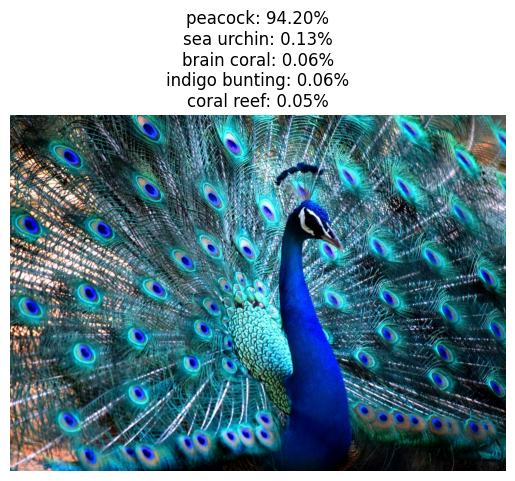

In [21]:
# visualize image and prediction
def visualize(image_path, pred, labels):
  image=Image.open(image_path)
  plt.imshow(image)
  plt.axis('off')

  # get 5 predictions
  top5_prob, top5_catid = torch.topk(pred, 5)
  top5_labels = [labels[i] for i in top5_catid]

  # show predictions
  plt.title('\n'.join([f'{label}: {prob:.2%}' for label, prob in zip(top5_labels, top5_prob)]))
  plt.show()

# example usage
image_path='/content/peacock.jpg'
image_tensor=transform_image(image_path)
predictions=predict(image_tensor, model)
visualize(image_path, predictions, labels)

In [12]:
labels

['tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen',
 'ostrich',
 'brambling',
 'goldfinch',
 'house finch',
 'junco',
 'indigo bunting',
 'robin',
 'bulbul',
 'jay',
 'magpie',
 'chickadee',
 'water ouzel',
 'kite',
 'bald eagle',
 'vulture',
 'great grey owl',
 'European fire salamander',
 'common newt',
 'eft',
 'spotted salamander',
 'axolotl',
 'bullfrog',
 'tree frog',
 'tailed frog',
 'loggerhead',
 'leatherback turtle',
 'mud turtle',
 'terrapin',
 'box turtle',
 'banded gecko',
 'common iguana',
 'American chameleon',
 'whiptail',
 'agama',
 'frilled lizard',
 'alligator lizard',
 'Gila monster',
 'green lizard',
 'African chameleon',
 'Komodo dragon',
 'African crocodile',
 'American alligator',
 'triceratops',
 'thunder snake',
 'ringneck snake',
 'hognose snake',
 'green snake',
 'king snake',
 'garter snake',
 'water snake',
 'vine snake',
 'night snake',
 'boa constrictor',
 'rock python',
 'Indian cobr